In [10]:
from pathlib import Path
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

In [3]:
PROJECT_ROOT = Path.cwd().parent
DATA_PATH = PROJECT_ROOT / "data" / "wesad_wrist_features_all_conditions.csv"
OUTPUT_DIR = PROJECT_ROOT / "outputs"
TABLES_DIR = OUTPUT_DIR / "tables"
TABLES_DIR.mkdir(parents=True, exist_ok=True)

# Initial inspection of the dataset

In [36]:

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
print("\nDataset information:")
df.info()

Dataset shape: (2887, 44)

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 2887 entries, 0 to 2886
Data columns (total 44 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   subject             2887 non-null   str    
 1   window_id           2887 non-null   int64  
 2   start_time          2887 non-null   float64
 3   end_time            2887 non-null   float64
 4   label               2887 non-null   int64  
 5   label_name          2887 non-null   str    
 6   BVP_mean            2887 non-null   float64
 7   BVP_std             2887 non-null   float64
 8   BVP_min             2887 non-null   float64
 9   BVP_max             2887 non-null   float64
 10  BVP_energy          2887 non-null   float64
 11  BVP_rms             2887 non-null   float64
 12  BVP_skew            2887 non-null   float64
 13  BVP_kurtosis        2887 non-null   float64
 14  BVP_peak_count      2887 non-null   int64  
 15  BVP_SDNN          

# Extract input features and metadata

In [37]:

# Original label mapping for the four-class task
CLASS_NAMES = {
    1: "Baseline",
    2: "Stress",
    3: "Amusement",
    4: "Meditation",
}

# Metadata and target columns are not input features
metadata_columns = [
    "subject",
    "window_id",
    "start_time",
    "end_time",
    "label",
    "label_name",
]

missing_required = [
    col for col in metadata_columns
    if col not in df.columns
]

if missing_required:
    raise ValueError(
        f"Required columns are missing: {missing_required}"
    )

# Verify the original labels and their names
observed_labels = set(df["label"].dropna().unique())
expected_labels = set(CLASS_NAMES.keys())

print("\nLabel-name correspondence:")
display(
    df.groupby("label", dropna=False)["label_name"]
      .agg(lambda x: ", ".join(sorted(x.dropna().astype(str).unique())))
      .to_frame("label_name")
)

if observed_labels != expected_labels:
    raise ValueError(
        "The observed labels do not match the expected four classes. "
        "Inspect the label mapping before continuing."
    )

# Numeric predictors only, excluding metadata and target
feature_columns = [
    col for col in df.select_dtypes(include=np.number).columns
    if col not in metadata_columns
]

X = df[feature_columns]
y = df["label"]
groups = df["subject"]

print("\nNumber of input features:", len(feature_columns))
print("Number of target classes:", y.nunique())
print("Number of subjects:", groups.nunique())

print("\nFeatures:")
for feature in feature_columns:
    print("-", feature)

# Save the feature list
pd.DataFrame({"feature": feature_columns}).to_csv(
    TABLES_DIR / "feature_list.csv",
    index=False
)



Label-name correspondence:


,label_name
label,
1,baseline
2,stress
3,amusement
4,meditation



Number of input features: 38
Number of target classes: 4
Number of subjects: 15

Features:
- BVP_mean
- BVP_std
- BVP_min
- BVP_max
- BVP_energy
- BVP_rms
- BVP_skew
- BVP_kurtosis
- BVP_peak_count
- BVP_SDNN
- BVP_RMSSD
- EDA_mean
- EDA_std
- EDA_min
- EDA_max
- EDA_range
- EDA_slope
- EDA_auc
- EDA_tonic_slope
- EDA_phasic_std
- EDA_SCR_count
- EDA_SCR_amp_sum
- EDA_SCR_amp_mean
- TEMP_mean
- TEMP_std
- TEMP_min
- TEMP_max
- TEMP_trend
- ACC_x_mean
- ACC_x_std
- ACC_y_mean
- ACC_y_std
- ACC_z_mean
- ACC_z_std
- ACC_SMA
- ACC_VM_mean
- ACC_VM_std
- ACC_activity_count


# Dataset statistics such as missing values, duplicate data etc.

In [39]:
# Missing values
missing_summary = pd.DataFrame({
    "missing_count": df.isnull().sum(),
    "missing_percentage": df.isnull().mean() * 100,
})

missing_summary = missing_summary.sort_values(
    "missing_percentage", ascending=False
)

missing_summary.to_csv(
    TABLES_DIR / "missing_values.csv"
)

# Duplicate rows
duplicate_rows = int(df.duplicated().sum())

# Duplicate subject-window combinations
duplicate_subject_windows = int(
    df.duplicated(subset=["subject", "window_id"]).sum()
)

# Unique participants and windows
overview = pd.DataFrame({
    "metric": [
        "Total windows",
        "Total columns",
        "Input features",
        "Unique subjects",
        "Unique labels",
        "Duplicate rows",
        "Duplicate subject-window pairs",
        "Missing cells",
    ],
    "value": [
        len(df),
        len(df.columns),
        len(feature_columns),
        df["subject"].nunique(),
        df["label"].nunique(),
        duplicate_rows,
        duplicate_subject_windows,
        int(df.isnull().sum().sum()),
    ],
})

print("\nDataset summary:")
display(overview)

overview.to_csv(
    TABLES_DIR / "dataset_overview.csv",
    index=False
)



Dataset summary:


,metric,value
0,Total windows,2887
1,Total columns,44
2,Input features,38
3,Unique subjects,15
4,Unique labels,4
5,Duplicate rows,0
6,Duplicate subject-window pairs,0
7,Missing cells,0


# Class distribution

In [14]:

class_distribution = (
    df["label"]
    .value_counts()
    .reindex(sorted(CLASS_NAMES.keys()), fill_value=0)
)

class_percentages = class_distribution / len(df) * 100

class_summary = pd.DataFrame({
    "class_name": [CLASS_NAMES[label] for label in class_distribution.index],
    "count": class_distribution.values,
    "percentage": class_percentages.values,
})

print("Class distribution:")
display(class_summary.round(2))

class_summary.to_csv(
    TABLES_DIR / "class_distribution.csv",
    index=False
)

imbalance_ratio = (
    class_distribution.max() / class_distribution.min()
)

print(f"Majority/minority class ratio: {imbalance_ratio:.2f}:1")
print(
    f"Majority class: "
    f"{CLASS_NAMES[class_distribution.idxmax()]}"
)
print(
    f"Minority class: "
    f"{CLASS_NAMES[class_distribution.idxmin()]}"
)


Class distribution:


,class_name,count,percentage
0,Baseline,1151,39.87
1,Stress,644,22.31
2,Amusement,347,12.02
3,Meditation,745,25.81


Majority/minority class ratio: 3.32:1
Majority class: Baseline
Minority class: Amusement


# Visualize class distribution

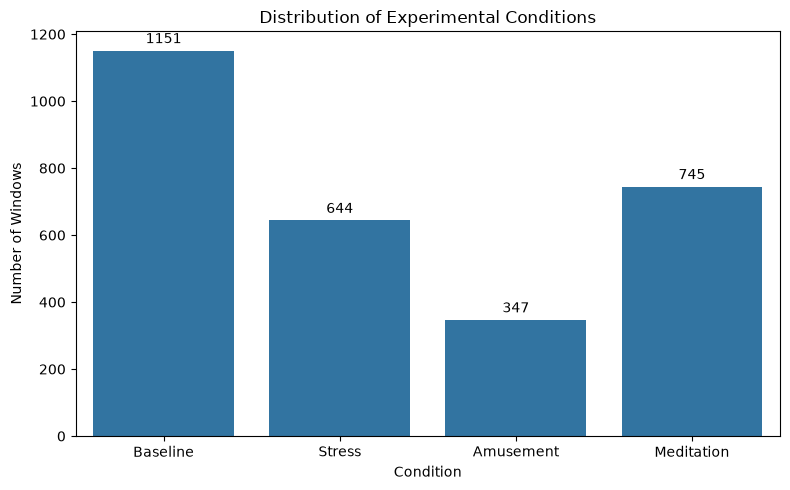

In [16]:

plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=class_summary,
    x="class_name",
    y="count",
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.0f", padding=3)

plt.title("Distribution of Experimental Conditions")
plt.xlabel("Condition")
plt.ylabel("Number of Windows")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figures" / "01_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Descriptive statistics

In [40]:
descriptive_stats = X.describe().T

descriptive_stats["median"] = X.median()
descriptive_stats["variance"] = X.var()
descriptive_stats["skewness"] = X.skew()
descriptive_stats["missing_count"] = X.isnull().sum()

descriptive_stats = descriptive_stats[
    [
        "count",
        "mean",
        "std",
        "min",
        "25%",
        "median",
        "50%",
        "75%",
        "max",
        "variance",
        "skewness",
        "missing_count",
    ]
]

descriptive_stats.to_csv(
    TABLES_DIR / "descriptive_statistics.csv"
)


In [18]:

class_feature_stats = (
    df.groupby("label")[feature_columns]
      .agg(["mean", "std", "median"])
)

class_feature_stats.to_csv(
    TABLES_DIR / "feature_statistics_by_class.csv"
)

print("Mean feature values by class:")
display(
    df.groupby("label")[feature_columns]
      .mean()
      .rename(index=CLASS_NAMES)
      .round(3)
)


Mean feature values by class:


,BVP_mean,BVP_std,BVP_min,BVP_max,BVP_energy,BVP_rms,BVP_skew,BVP_kurtosis,BVP_peak_count,BVP_SDNN,...,ACC_x_mean,ACC_x_std,ACC_y_mean,ACC_y_std,ACC_z_mean,ACC_z_std,ACC_SMA,ACC_VM_mean,ACC_VM_std,ACC_activity_count
label,,,,,,,,,,,,,,,,,,,,,
Baseline,-0.007,37.695,-166.771,156.782,3816805.135,37.696,-0.267,4.032,41.109,187.456,...,14.463,6.324,-4.370,5.840,12.483,9.195,94.986,63.608,1.770,83.132
Stress,-0.002,50.819,-225.126,218.958,8696982.880,50.820,-0.021,5.617,51.986,174.391,...,16.993,6.171,-9.526,6.085,2.851,9.265,93.130,63.805,4.197,87.714
Amusement,0.002,28.144,-131.762,119.353,2909992.638,28.144,-0.337,4.988,40.839,183.440,...,22.895,3.201,0.010,3.204,17.712,3.315,89.211,63.363,0.923,95.141
Meditation,-0.000,17.787,-61.315,52.520,937738.733,17.787,-0.448,1.504,38.411,164.650,...,14.681,1.196,1.087,1.157,16.218,1.164,88.722,63.648,0.511,119.369


# Distribution per subject

In [42]:

# Number of windows per subject
windows_per_subject = (
    df.groupby("subject")
      .size()
      .rename("number_of_windows")
      .sort_values(ascending=False)
)

windows_per_subject.to_csv(
    TABLES_DIR / "windows_per_subject.csv"
)

# Number of windows per subject and class
subject_class_counts = pd.crosstab(
    df["subject"],
    df["label"]
).reindex(columns=sorted(CLASS_NAMES.keys()), fill_value=0)

subject_class_counts.columns = [
    CLASS_NAMES[label]
    for label in subject_class_counts.columns
]

print("Windows per subject and class:")
display(subject_class_counts)

subject_class_counts.to_csv(
    TABLES_DIR / "subject_class_distribution.csv"
)


Windows per subject and class:


,Baseline,Stress,Amusement,Meditation
subject,,,,
S10,77,47,23,50
S11,77,44,23,50
S13,77,43,24,50
S14,77,44,23,50
S15,77,44,23,50
S16,77,43,23,50
S17,77,47,23,46
S2,75,40,23,49
S3,75,41,24,49


# Visualize class distribution across subjects

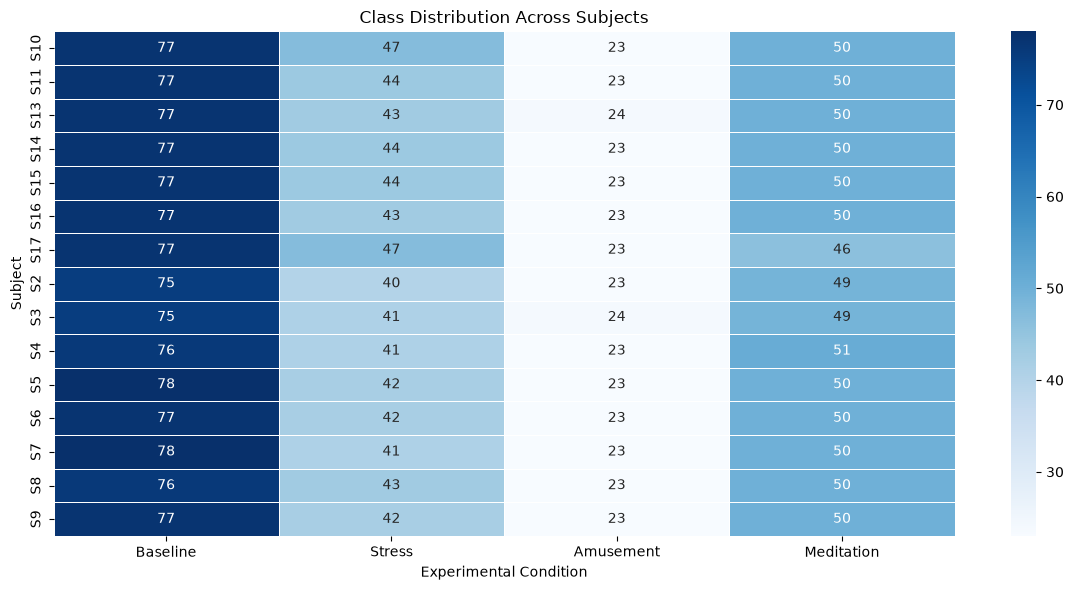

In [21]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    subject_class_counts,
    annot=True,
    fmt="d",
    cmap="Blues",
    linewidths=0.5
)

plt.title("Class Distribution Across Subjects")
plt.xlabel("Experimental Condition")
plt.ylabel("Subject")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figures" / "02_subject_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


# Distributions of representative input features 

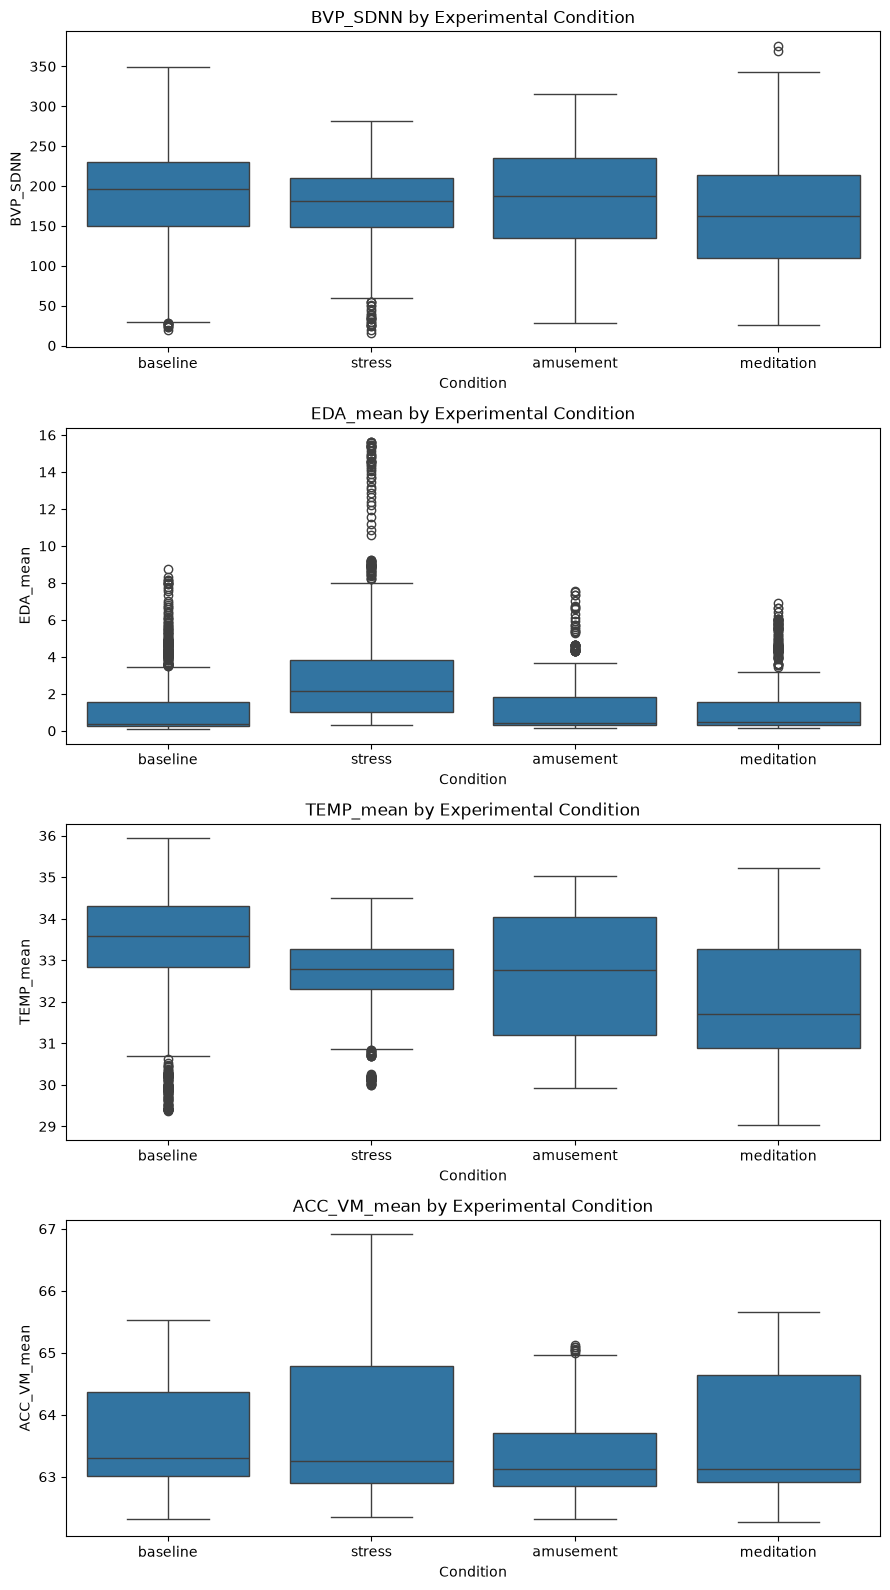

In [25]:

representative_features = [
    "BVP_SDNN",
    "EDA_mean",
    "TEMP_mean",
    "ACC_VM_mean",
]

representative_features = [
    feature for feature in representative_features
    if feature in feature_columns
]

if representative_features:
    fig, axes = plt.subplots(
        nrows=len(representative_features),
        ncols=1,
        figsize=(9, 4 * len(representative_features))
    )

    if len(representative_features) == 1:
        axes = [axes]

    for ax, feature in zip(axes, representative_features):
        sns.boxplot(
            data=df,
            x="label_name",
            y=feature,
            order=["baseline", "stress", "amusement", "meditation"],
            ax=ax
        )

        ax.set_title(f"{feature} by Experimental Condition")
        ax.set_xlabel("Condition")
        ax.set_ylabel(feature)

    plt.tight_layout()
    plt.savefig(
        OUTPUT_DIR / "figures" / "03_representative_feature_boxplots.png",
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()


# Correlation between features

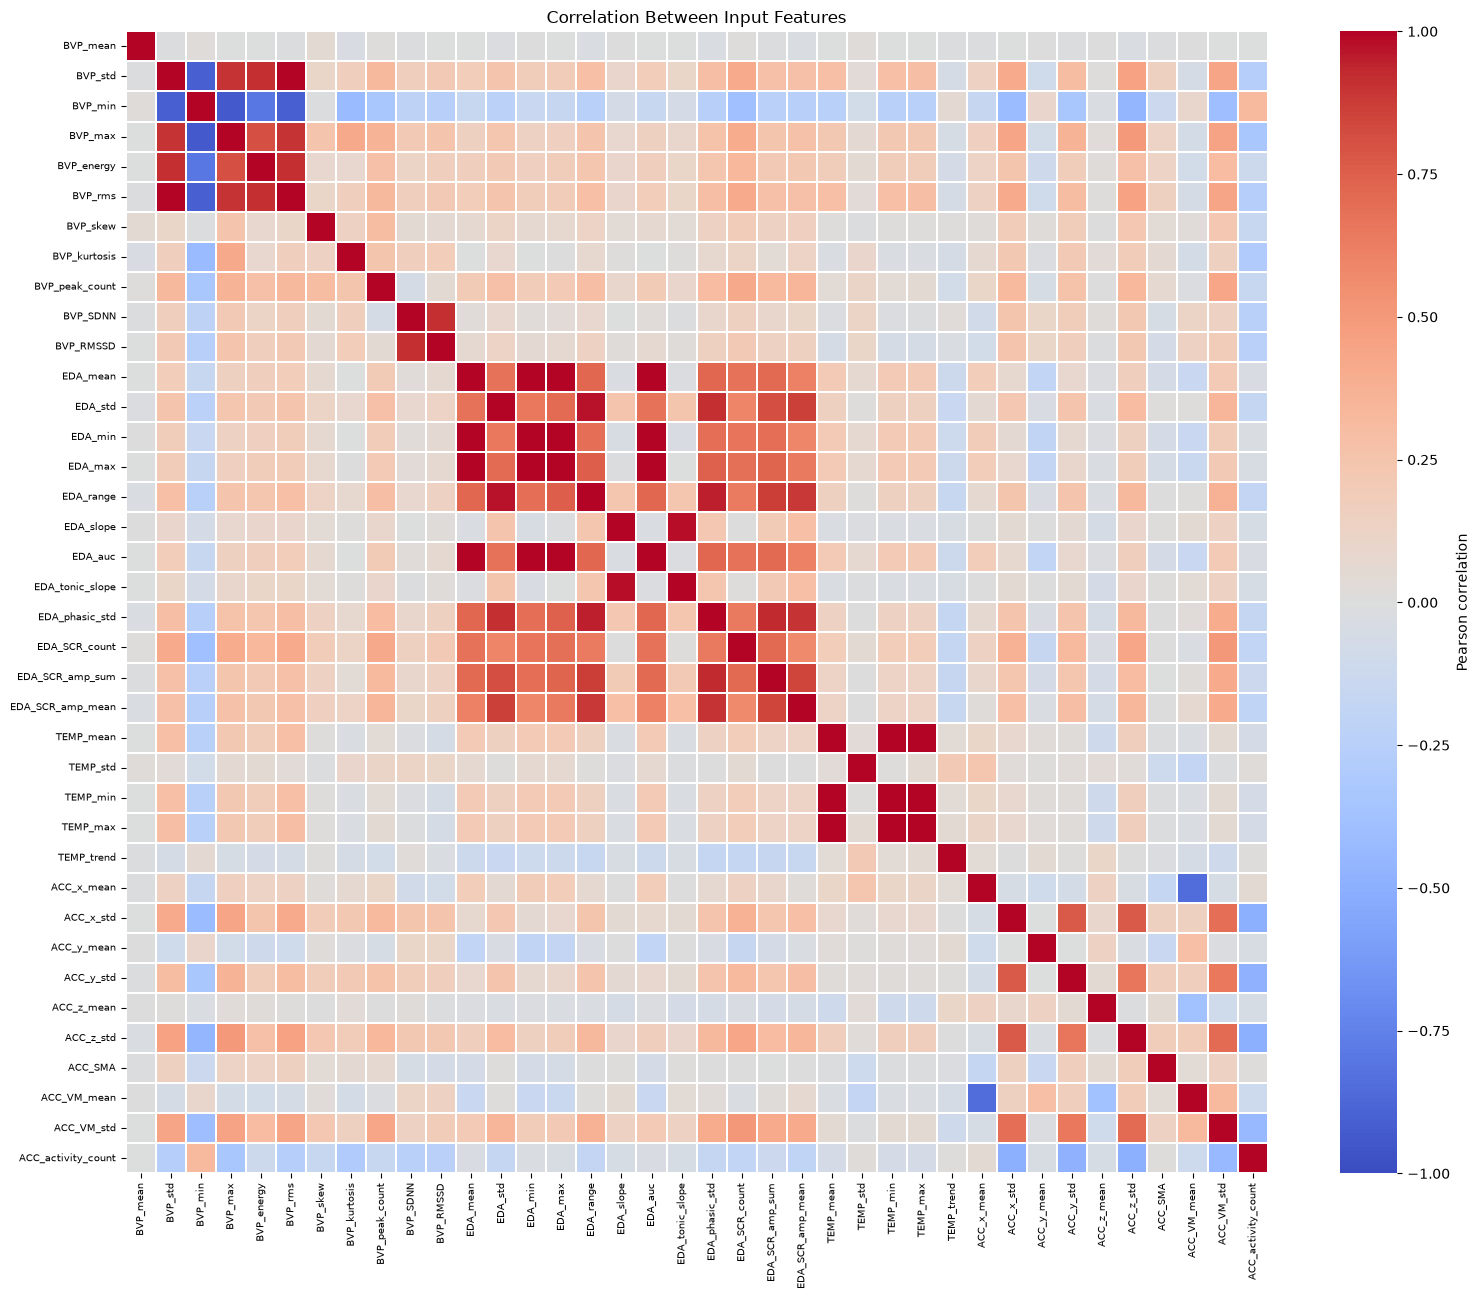

In [28]:

correlation_matrix = X.corr(method="pearson")

correlation_matrix.to_csv(
    TABLES_DIR / "feature_correlation_matrix.csv"
)

plt.figure(figsize=(16, 13))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.1,
    xticklabels=True,
    yticklabels=True,
    cbar_kws={"label": "Pearson correlation"}
)

plt.title("Correlation Between Input Features")
plt.xticks(rotation=90, fontsize=7)
plt.yticks(fontsize=7)
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figures" / "04_feature_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()


In [29]:

upper_triangle = correlation_matrix.where(
    np.triu(
        np.ones(correlation_matrix.shape, dtype=bool),
        k=1
    )
)

strong_correlations = (
    upper_triangle.stack()
    .rename("correlation")
    .reset_index()
)

strong_correlations.columns = [
    "feature_1",
    "feature_2",
    "correlation"
]

strong_correlations["absolute_correlation"] = (
    strong_correlations["correlation"].abs()
)

strong_correlations = strong_correlations.sort_values(
    "absolute_correlation",
    ascending=False
)

print("Top 15 most strongly correlated feature pairs:")
display(strong_correlations.head(15).round(4))

strong_correlations.to_csv(
    TABLES_DIR / "feature_correlations_ranked.csv",
    index=False
)


Top 15 most strongly correlated feature pairs:


,feature_1,feature_2,correlation,absolute_correlation
43,BVP_std,BVP_rms,1.0000,1.0000
435,EDA_mean,EDA_auc,1.0000,1.0000
900,TEMP_mean,TEMP_max,0.9998,0.9998
899,TEMP_mean,TEMP_min,0.9998,0.9998
976,TEMP_min,TEMP_max,0.9994,0.9994
432,EDA_mean,EDA_max,0.9989,0.9989
549,EDA_max,EDA_auc,0.9989,0.9989
431,EDA_mean,EDA_min,0.9988,0.9988
511,EDA_min,EDA_auc,0.9988,0.9988
508,EDA_min,EDA_max,0.9964,0.9964


In [43]:
# pip install umap-learn

# UMAP Projection

/Users/croitoruandreea/Desktop/ml-course-project/.venv/lib/python3.13/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


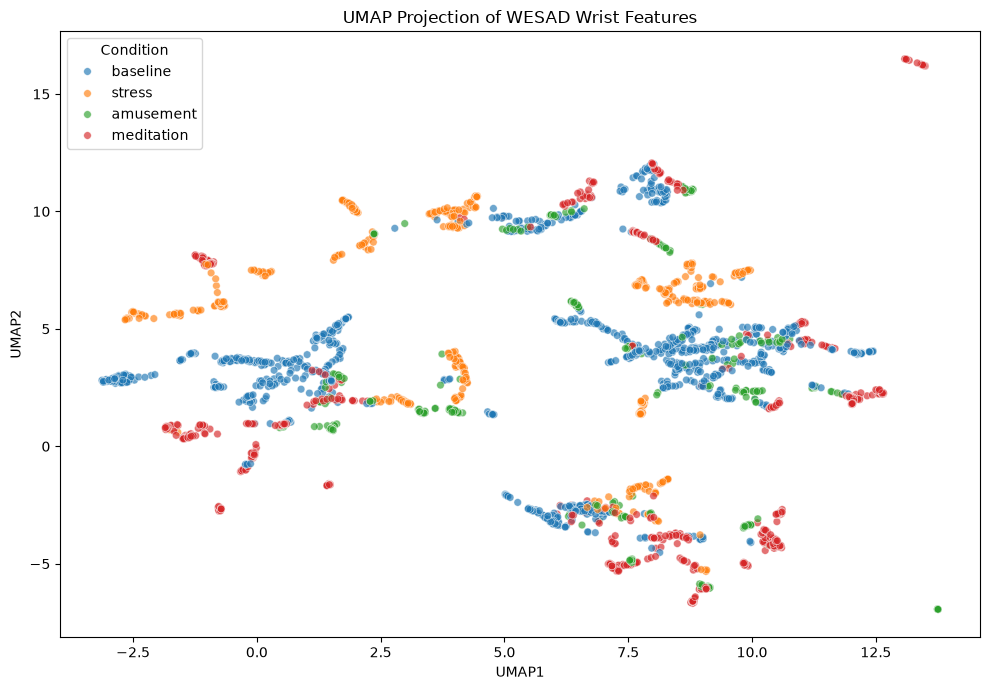

In [34]:

import umap
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler

# Standardize the 38 input features
X_scaled = StandardScaler().fit_transform(X)

# Reduce the data to two dimensions
umap_model = umap.UMAP(
    n_components=2,
    n_neighbors=15,
    min_dist=0.1,
    metric="euclidean",
    random_state=42
)

X_umap = umap_model.fit_transform(X_scaled)

# Build the visualization dataframe
umap_df = pd.DataFrame({
    "UMAP1": X_umap[:, 0],
    "UMAP2": X_umap[:, 1],
    "Condition": df["label_name"].values
})

# Plot
plt.figure(figsize=(10, 7))

sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="Condition",
    hue_order=["baseline", "stress", "amusement", "meditation"],
    alpha=0.65,
    s=30
)

plt.title("UMAP Projection of WESAD Wrist Features")
plt.xlabel("UMAP1")
plt.ylabel("UMAP2")
plt.legend(title="Condition")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR / "figures" / "06_umap_projection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# Compute F-scores

Top 10 features according to the F-test:


,feature,F_score,p_value
0,BVP_peak_count,685.502646,0.0
1,EDA_SCR_count,371.577700,0.0
2,ACC_VM_std,328.570384,0.0
3,EDA_SCR_amp_mean,316.781998,0.0
4,EDA_phasic_std,278.684741,0.0
5,EDA_SCR_amp_sum,254.823148,0.0
6,EDA_range,246.211872,0.0
7,ACC_z_std,240.061946,0.0
8,EDA_std,217.762212,0.0
9,BVP_max,172.125338,0.0


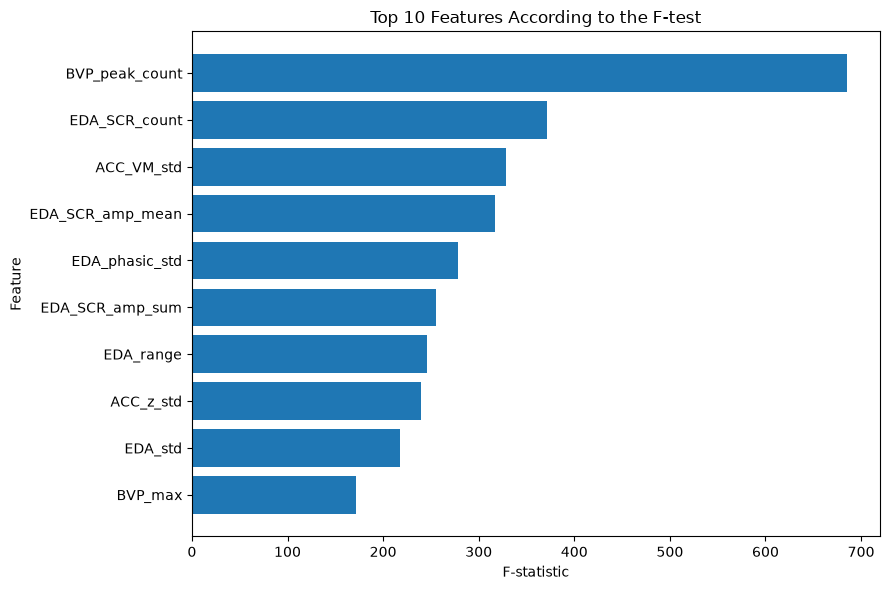

In [35]:

from sklearn.feature_selection import f_classif
import pandas as pd
import matplotlib.pyplot as plt

# Compute univariate F-scores for the four-class target
f_scores, p_values = f_classif(X, y)

feature_scores = pd.DataFrame({
    "feature": feature_columns,
    "F_score": f_scores,
    "p_value": p_values,
})

feature_scores = feature_scores.sort_values(
    "F_score",
    ascending=False
).reset_index(drop=True)

print("Top 10 features according to the F-test:")
display(feature_scores.head(10).round(6))

# Save the complete ranking
feature_scores.to_csv(
    TABLES_DIR / "f_test_feature_ranking.csv",
    index=False
)

# Visualize the top 10 features
top_features = feature_scores.head(10).sort_values(
    "F_score",
    ascending=True
)

plt.figure(figsize=(9, 6))
plt.barh(
    top_features["feature"],
    top_features["F_score"]
)

plt.xlabel("F-statistic")
plt.ylabel("Feature")
plt.title("Top 10 Features According to the F-test")
plt.tight_layout()

plt.savefig(
    OUTPUT_DIR/ "figures" / "07_f_test_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
